# Korpus aufbauen

In [389]:
import os

corpus = [] #initial empty list

os.getcwd() #get current path

data_folder = os.path.join(os.getcwd(), "korpus") #join current path with directory name
print(list(os.walk(data_folder))) #check files inside of chosen directory

for root, folders, files in os.walk(data_folder): #structure of list is root -> folders -> files
    for file in files:
        path = os.path.join(root, file)
        with open(path, encoding="utf8") as input: #encode in utf8 for special characters like ä.ü,ö,ß
            corpus.append(input.read()) #append every file as new list-item
input.close()

print(len(corpus),"Texte wurden erfolgreich in den Korpus geladen.")


[('c:\\workspace\\nlp-lernen\\korpus', [], ['aanrud-sidsel_langroeckchen.txt', 'achleitner-Aus_Kroatien.txt', 'achleitner-Bergrichters_Erdenwallen.txt', 'achleitner-Celsissimus.txt', 'achleitner-Im_gruenen_Tann.txt', 'achleitner-Unter_den_Hohen_Tauern.txt', 'alarcon-Der Dreispitz.txt', 'alberti-Japanische Märchen.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 40.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 42.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 56.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 63.txt', 'goethe-die_leiden_des_jungen_werther_band1.txt', 'goethe-die_leiden_des_jungen_werther_band2.txt', 'goethe-faust1.txt', 'goethe-faust2.txt', 'goethe-wahlverwandtschaften.txt', 'goethe-wilhelm_meisters_lehrjahre_band1.txt', 'goethe-wilhelm_meisters_wanderjahre_band1.txt', 'heine-Almansor.txt', 'kafka-das_urteil.txt', 'kafka-der_prozess.txt', 'kafka-die_verwandlung.txt', 'kafka-landarzt.txt', 'kafka-urteil.txt', 'kafka-v

In [390]:
import nltk
from nltk.text import Text
from nltk.tokenize import word_tokenize
from nltk.probability import FreqDist
from nltk.util import ngrams
from nltk.tokenize import word_tokenize
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_distances, cosine_similarity
import numpy as np
import spacy
from textstat.textstat import textstatistics
import pyphen
import re

corpus_list = []
#corpus_vec = []
corpus_name = []

def number_words(text):
    text_words = re.findall(r'\b\w+\b', text.lower()) #regex um alle wörter zu finden und Satzzeichenzu entfernen; außerdem lower den Text
    return len(text_words)

def avg_word_len(text):
    text_words = re.findall(r'\b\w+\b', text.lower()) #regex um alle wörter zu finden und Satzzeichenzu entfernen; außerdem lower den Text
    avg_word_len = sum(len(word) for word in text_words) / len(text_words)
    return round(avg_word_len,1)

def number_sentences(text):
    sentences = nltk.sent_tokenize(text) #tokenize in sentences
    return len(sentences)

def avg_sen_len(text):
    avg_sen_len = round(number_words(text) / number_sentences(text),1) #average sentence length
    return avg_sen_len

#Type-Token-Ratio (TTR)
def ttr(tokens):
    return len(set(tokens)) / len(tokens) if tokens else 0 #make set without duplicates and divide with all tokens (incl. duplicates); if list is empty, dont divide with 0 just say, its 0

def punctuations(tokens):
    excl = 0
    quest = 0
    pct = 0
    com = 0
    semic = 0
    colo = 0

    for i in tokens:
        if i == "!":
            excl += 1
        if i == "?":
            quest += 1
        if i == ".":
            pct += 1
        if i == ",":
            com += 1
        if i == ";":
            semic += 1
        if i == ":":
            colo += 1

    erg_excl = excl / len(tokens)
    erg_quest = quest / len(tokens)
    erg_pct = pct / len(tokens)
    erg_com = com / len(tokens)
    erg_semic = semic / len(tokens)
    erg_colo = colo / len(tokens)

    return erg_excl, erg_quest, erg_pct, erg_com, erg_semic, erg_colo

def syllables_count(text, sprache='de_DE'):
    dic = pyphen.Pyphen(lang=sprache)
    worte = text.split()
    #print(worte)
    silben_gesamt = 0
    global syll1
    syll1 = 0
    
    for wort in worte:
        silben = dic.inserted(wort).split('-')
        #print(silben, len(silben))
        if len(silben) == 1:
            syll1 += 1
            #print("Silbe hier:",len(silben),"---->",silben)
        silben_gesamt += len(silben)

    return silben_gesamt

def avg_syllables_per_word(var3):
    #print("Übermittel var3:",var3)
    words = re.findall(r'\b\w+\b', var3.lower())
    avg_syllables = syllables_count(var3) / len(words)
    #print("Silben:",syllables_count(var3))
    #print("Wörter:",len(words))
    return round(avg_syllables, 1)

def flesch_reading_ease_ger(asl, asw):
    
    fre = 180 - asl - (58.5 - asw)
    
    return round(fre,2)

def wiener_sachtext_formel(text):
    syll = 0
    ms = 0 
    sl = 0
    iw = 0
    es = 0
    words6 = 0
    global syll1

    if syllables_count(text) > 3:
        syll += 1
    ms = syll / number_words(text) * 100
    sl = avg_sen_len(text)

    words = re.findall(r'\b\w+\b', text.lower())
    for word in words:
        if len(word) > 5:
            #print("hier:",len(word),"---->",word)
            words6 += 1
    iw = words6 / number_words(text)
    es = syll1 / number_words(text) * 100
    # print("MS:",ms)
    # print("SL:",sl)
    # print("SL:",sl)
    # print("IW:",iw)
    # print("ES:",es)

    # print("syll1:",syll1)
    # print("# Words:",number_words(text))
    #print("Formel: 0.1935 *", ms,"+ 0.1672 *", sl,"+ 0.1297 *", iw,"- 0.0327 *", es," - 0.875")

    wsf = 0.1935 * ms + 0.1672 * sl + 0.1297 * iw - 0.0327 * es - 0.875
    return round(wsf,2)

def ngram_haeufigkeit(text):
    # Kleinbuchstaben & Tokenisierung
    tokens = word_tokenize(text.lower())

    # Bigramme & Trigramme erzeugen
    bigramme = list(ngrams(tokens, 2))
    trigramme = list(ngrams(tokens, 3))

    # Häufigkeiten zählen
    bigram_haeufigkeit = Counter(bigramme)
    trigram_haeufigkeit = Counter(trigramme)

    # Ergebnisse anzeigen
    print(f"Anzahl eindeutiger Bigramme: {len(bigram_haeufigkeit)}")
    print(f"Anzahl eindeutiger Trigramme: {len(trigram_haeufigkeit)}\n")

    print("Top 5 Bigramme:")
    for bigram, count in bigram_haeufigkeit.most_common(5):
        print(f"{bigram} → {count} Mal")

    print("\nTop 5 Trigramme:")
    for trigram, count in trigram_haeufigkeit.most_common(5):
        print(f"{trigram} → {count} Mal")



In [391]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(analyzer='word', ngram_range=(1, 2), binary=True)
X = vectorizer.fit_transform(corpus)

In [392]:
dist_matrix = cosine_distances(X)

for i, text in enumerate(corpus):
    print(f"Vektor für Text {i} →",
          X[i].toarray().reshape(-1)[:37]) 

print("\nCosine-Distanz-Matrix:")
print(dist_matrix)

Vektor für Text 0 → [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 1 → [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0]
Vektor für Text 2 → [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 3 → [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 4 → [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 5 → [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 6 → [0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 7 → [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 8 → [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 9 → [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0]
Vektor für Text 10 → [0 0 0 0 0 0 0 0 0 

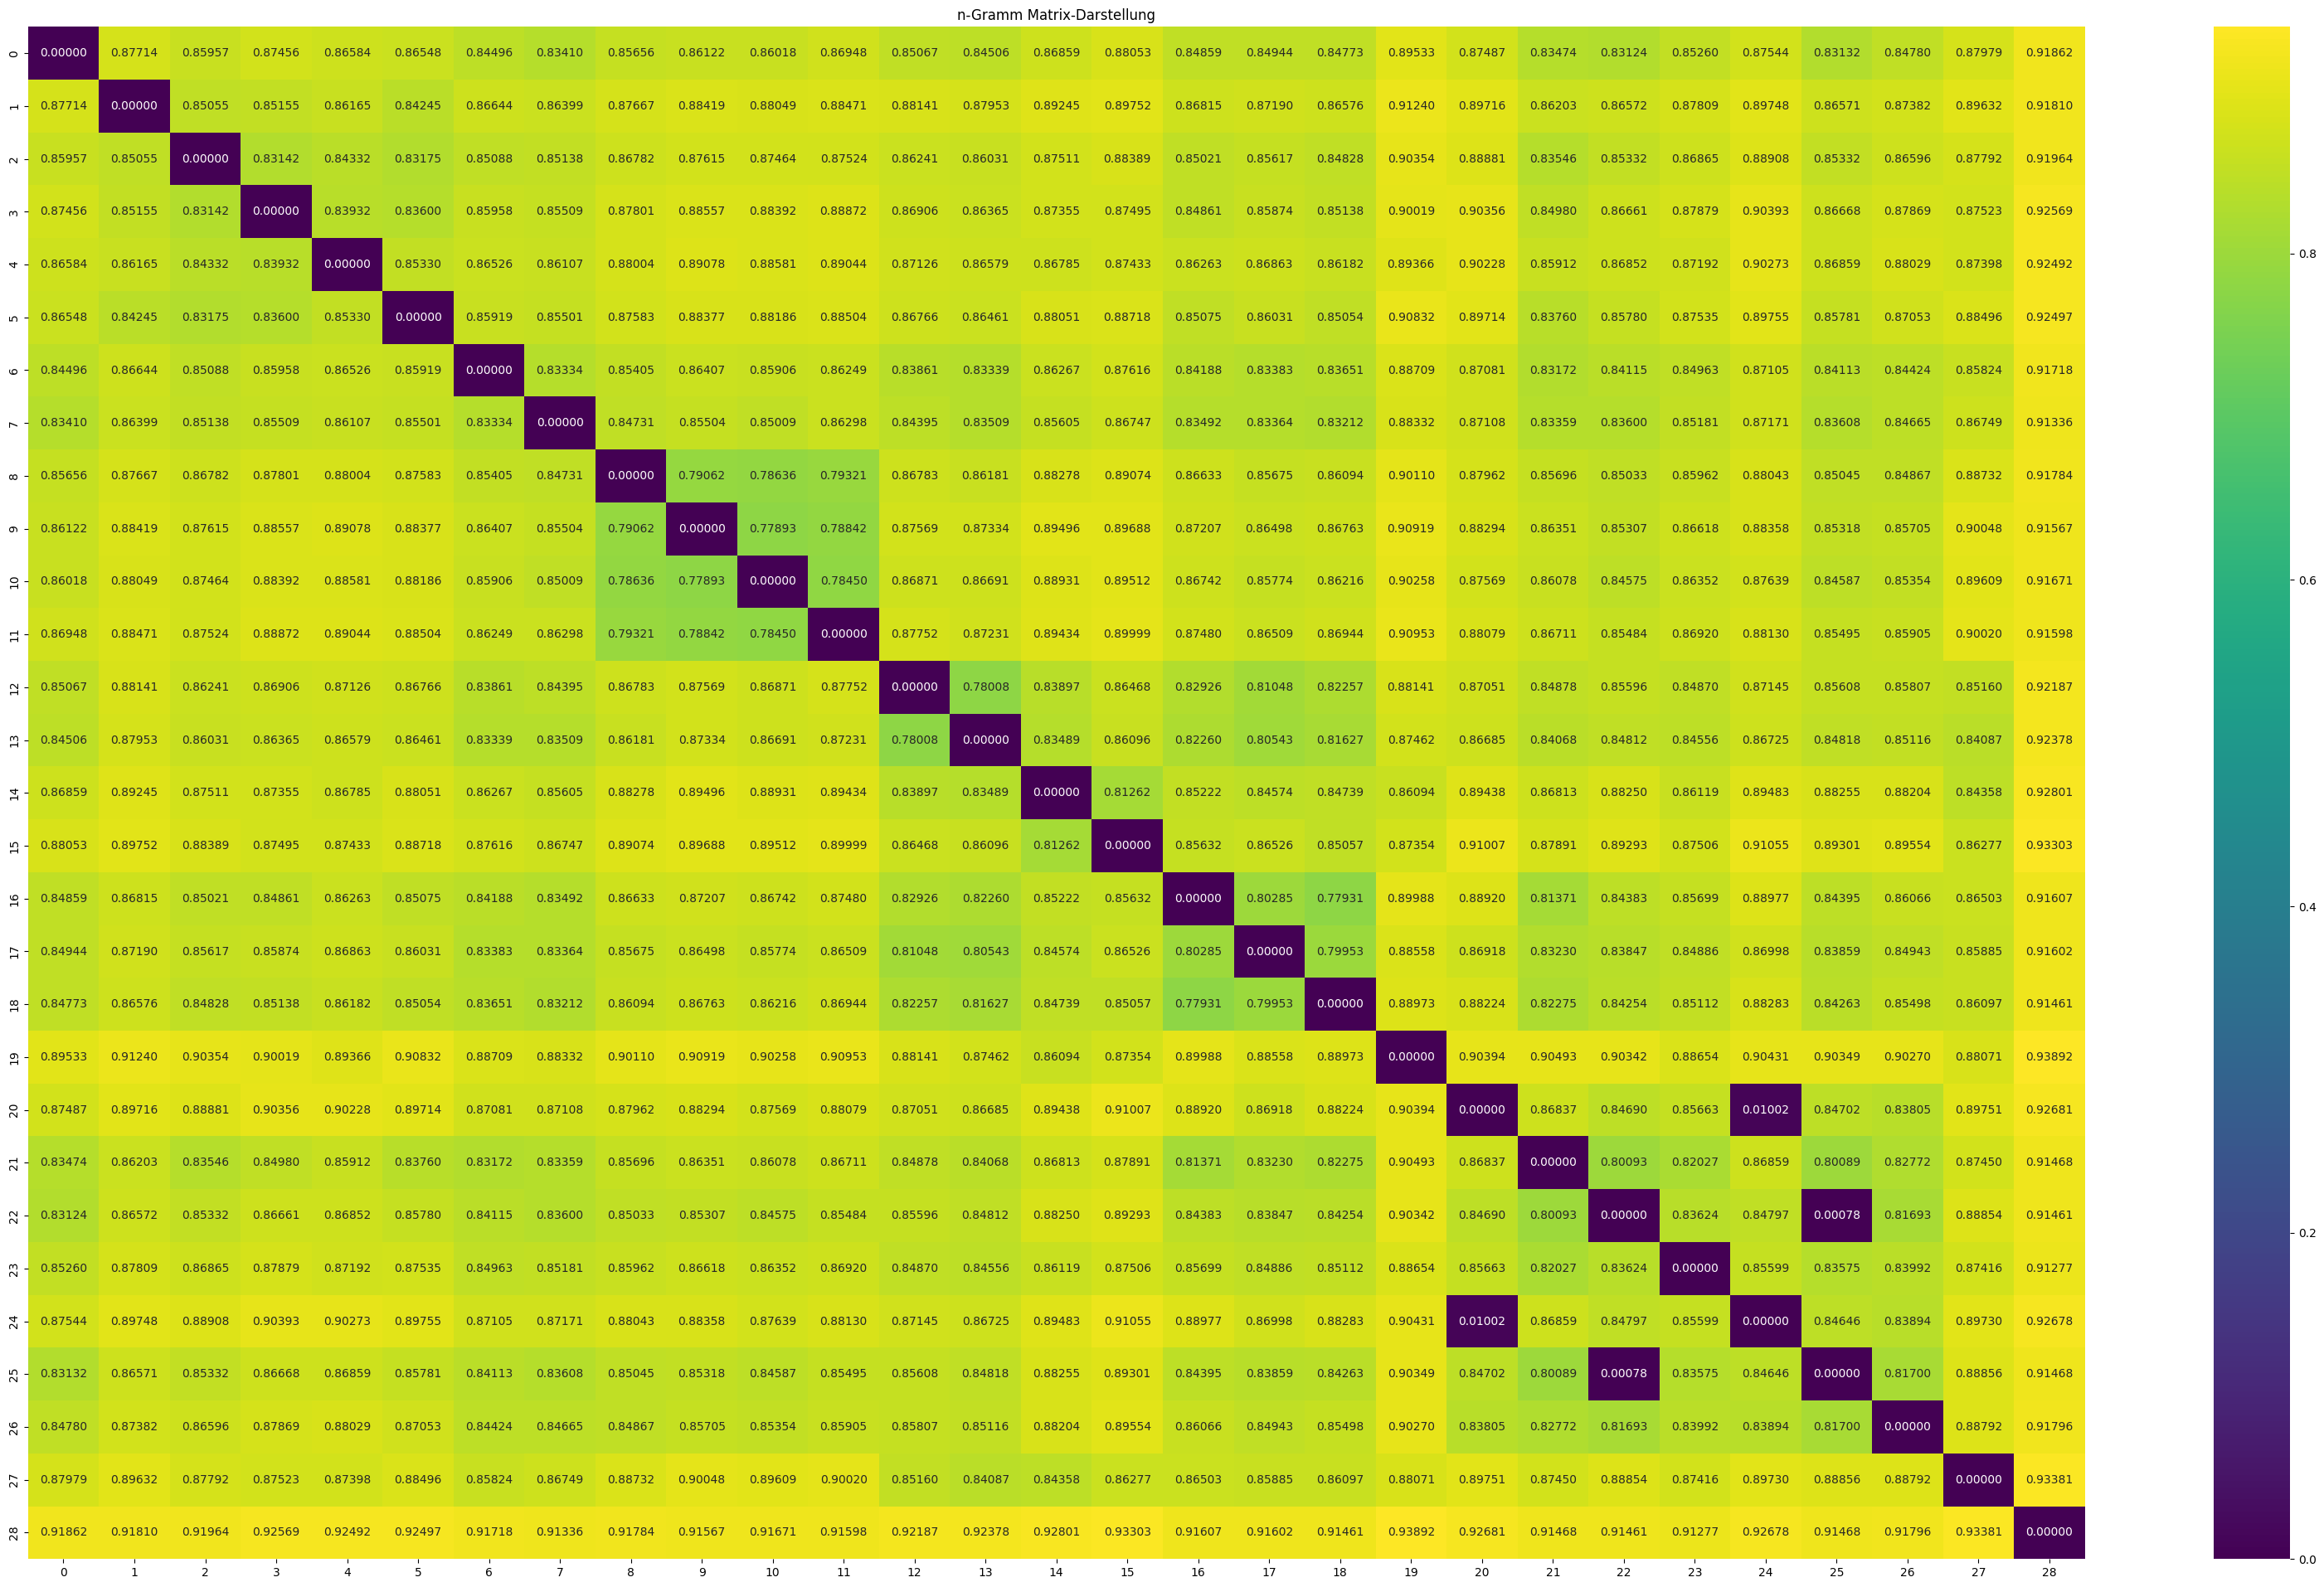

In [393]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame(dist_matrix)

plt.figure(figsize=(40, 24))
sns.heatmap(df, annot=True, fmt=".5f", cmap="viridis")
plt.title("n-Gramm Matrix-Darstellung")
plt.show()


In [394]:
for text in corpus:

    nltk_text = Text(nltk.word_tokenize(text.lower())) #lower, damit es keine Doppelungen beim zählen später gibt
    #nltk_text_words = word_tokenize(text)
    
    wordcount = number_words(text)
    sentencescount = number_sentences(text)
    print(wordcount,sentencescount)

    avgsenlen = avg_sen_len(text) #average sentence length
    #print(avg_sen_len)
    avgwordlen = avg_word_len(text)
    #print(avg_word_len)
    #print(avgwordlen,avgsenlen)


    ttr_erg = round(ttr(nltk_text),2)
    avg_punct = punctuations(nltk_text)
    
    avg_syll = avg_syllables_per_word(text)
    fre_ger = flesch_reading_ease_ger(avgsenlen, avg_syll)
    wsf = wiener_sachtext_formel(text)
    print(avgwordlen, avgsenlen, avg_syll, wsf, ttr_erg)
    print(ngram_haeufigkeit(text))

    corpus_list.append([avgwordlen, avgsenlen, avg_syll, wsf, fre_ger, ttr_erg, round(avg_punct[0],3), round(avg_punct[1],3), round(avg_punct[2],3), round(avg_punct[3],3), round(avg_punct[4],3), round(avg_punct[5],3)]) #All Features
    #corpus_list.append([avgwordlen, avgsenlen, avg_syll, wsf, ttr_erg])
    corpus_name.append(nltk_text)

    print("-----------------------------------------------")

#print("Corpuslist:",corpus_list)

27616 1213
4.8 22.8 1.6 1.11 0.14
Anzahl eindeutiger Bigramme: 18890
Anzahl eindeutiger Trigramme: 28929

Top 5 Bigramme:
(',', 'und') → 336 Mal
(',', 'daß') → 194 Mal
(',', 'die') → 161 Mal
(',', 'als') → 107 Mal
(',', 'das') → 88 Mal

Top 5 Trigramme:
(',', 'daß', 'sie') → 68 Mal
('*', '*', '*') → 56 Mal
(',', 'als', 'sie') → 27 Mal
('.', 'ja', ',') → 24 Mal
(',', 'daß', 'er') → 22 Mal
None
-----------------------------------------------
33281 1853
5.8 18.0 1.9 0.63 0.22
Anzahl eindeutiger Bigramme: 28450
Anzahl eindeutiger Trigramme: 38070

Top 5 Bigramme:
(',', 'daß') → 218 Mal
('!', '“') → 199 Mal
(',', 'die') → 150 Mal
(',', 'der') → 125 Mal
('.', 'der') → 121 Mal

Top 5 Trigramme:
('!', '“', '„') → 65 Mal
(',', 'daß', 'der') → 46 Mal
('?', '“', '„') → 32 Mal
(',', 'daß', 'die') → 26 Mal
(',', 'daß', 'er') → 13 Mal
None
-----------------------------------------------
46250 2530
5.5 18.3 1.8 0.56 0.17
Anzahl eindeutiger Bigramme: 35653
Anzahl eindeutiger Trigramme: 50585

Top 5 Bi

In [395]:
corpus_list

[[4.8, 22.8, 1.6, 1.11, 100.3, 0.14, 0.003, 0.002, 0.033, 0.082, 0.011, 0.003],
 [5.8, 18.0, 1.9, 0.63, 105.4, 0.22, 0.013, 0.003, 0.036, 0.061, 0.005, 0.003],
 [5.5, 18.3, 1.8, 0.56, 105.0, 0.17, 0.022, 0.007, 0.032, 0.062, 0.001, 0.002],
 [5.5, 23.2, 1.8, 1.43, 100.1, 0.16, 0.018, 0.004, 0.024, 0.071, 0.002, 0.004],
 [5.3, 19.8, 1.7, 0.72, 103.4, 0.17, 0.017, 0.004, 0.03, 0.066, 0.004, 0.004],
 [5.5, 15.7, 1.8, 0.18, 107.6, 0.15, 0.032, 0.005, 0.029, 0.062, 0.002, 0.005],
 [5.0, 20.4, 1.7, 0.8, 102.8, 0.17, 0.01, 0.007, 0.029, 0.087, 0.002, 0.002],
 [4.9, 24.2, 1.6, 1.45, 98.9, 0.16, 0.007, 0.002, 0.032, 0.07, 0.006, 0.005],
 [5.4, 15.8, 1.8, 0.16, 107.5, 0.2, 0.001, 0.003, 0.051, 0.073, 0.0, 0.0],
 [5.5, 16.4, 1.8, 0.29, 106.9, 0.2, 0.001, 0.002, 0.049, 0.074, 0.0, 0.0],
 [5.4, 16.4, 1.8, 0.3, 106.9, 0.21, 0.001, 0.001, 0.051, 0.072, 0.0, 0.0],
 [5.5, 15.1, 1.8, 0.07, 108.2, 0.21, 0.001, 0.001, 0.054, 0.073, 0.0, 0.0],
 [4.9, 23.9, 1.7, 1.39, 99.3, 0.19, 0.01, 0.003, 0.023, 0.094, 0

In [396]:
corpus_vec = np.array(corpus_list)
corpus_matrix = cosine_distances(corpus_vec)

In [397]:
corpus_matrix = cosine_distances(corpus_vec)
corpus_matrix

array([[0.00000000e+00, 1.51681195e-03, 1.32335005e-03, 3.91188744e-05,
        6.02068173e-04, 3.13138284e-03, 3.86240541e-04, 1.42081338e-04,
        3.04902401e-03, 2.57561763e-03, 2.57161671e-03, 3.64748270e-03,
        8.56246339e-05, 1.99616806e-03, 1.19767154e-02, 5.09236681e-03,
        1.58161995e-05, 2.66636668e-04, 3.93711495e-05, 4.19293928e-03,
        3.29244815e-04, 2.05120556e-04, 3.00237135e-03, 7.33857549e-05,
        3.58644604e-04, 3.10153534e-03, 1.11906750e-03, 7.92840696e-03,
        5.84623162e-03],
       [1.51681195e-03, 0.00000000e+00, 9.94683420e-06, 1.74335989e-03,
        2.09853638e-04, 3.09902755e-04, 3.80841568e-04, 2.55542666e-03,
        2.89387668e-04, 1.54189001e-04, 1.57428741e-04, 4.85391050e-04,
        2.28991499e-03, 8.82131520e-05, 5.13053076e-03, 1.12018764e-03,
        1.41526927e-03, 2.95783602e-03, 1.12282751e-03, 7.42288849e-04,
        4.42105493e-04, 2.78921729e-03, 8.66619921e-03, 9.26153781e-04,
        4.10359934e-04, 8.83406251e-03,

# Heatmap zeichnen

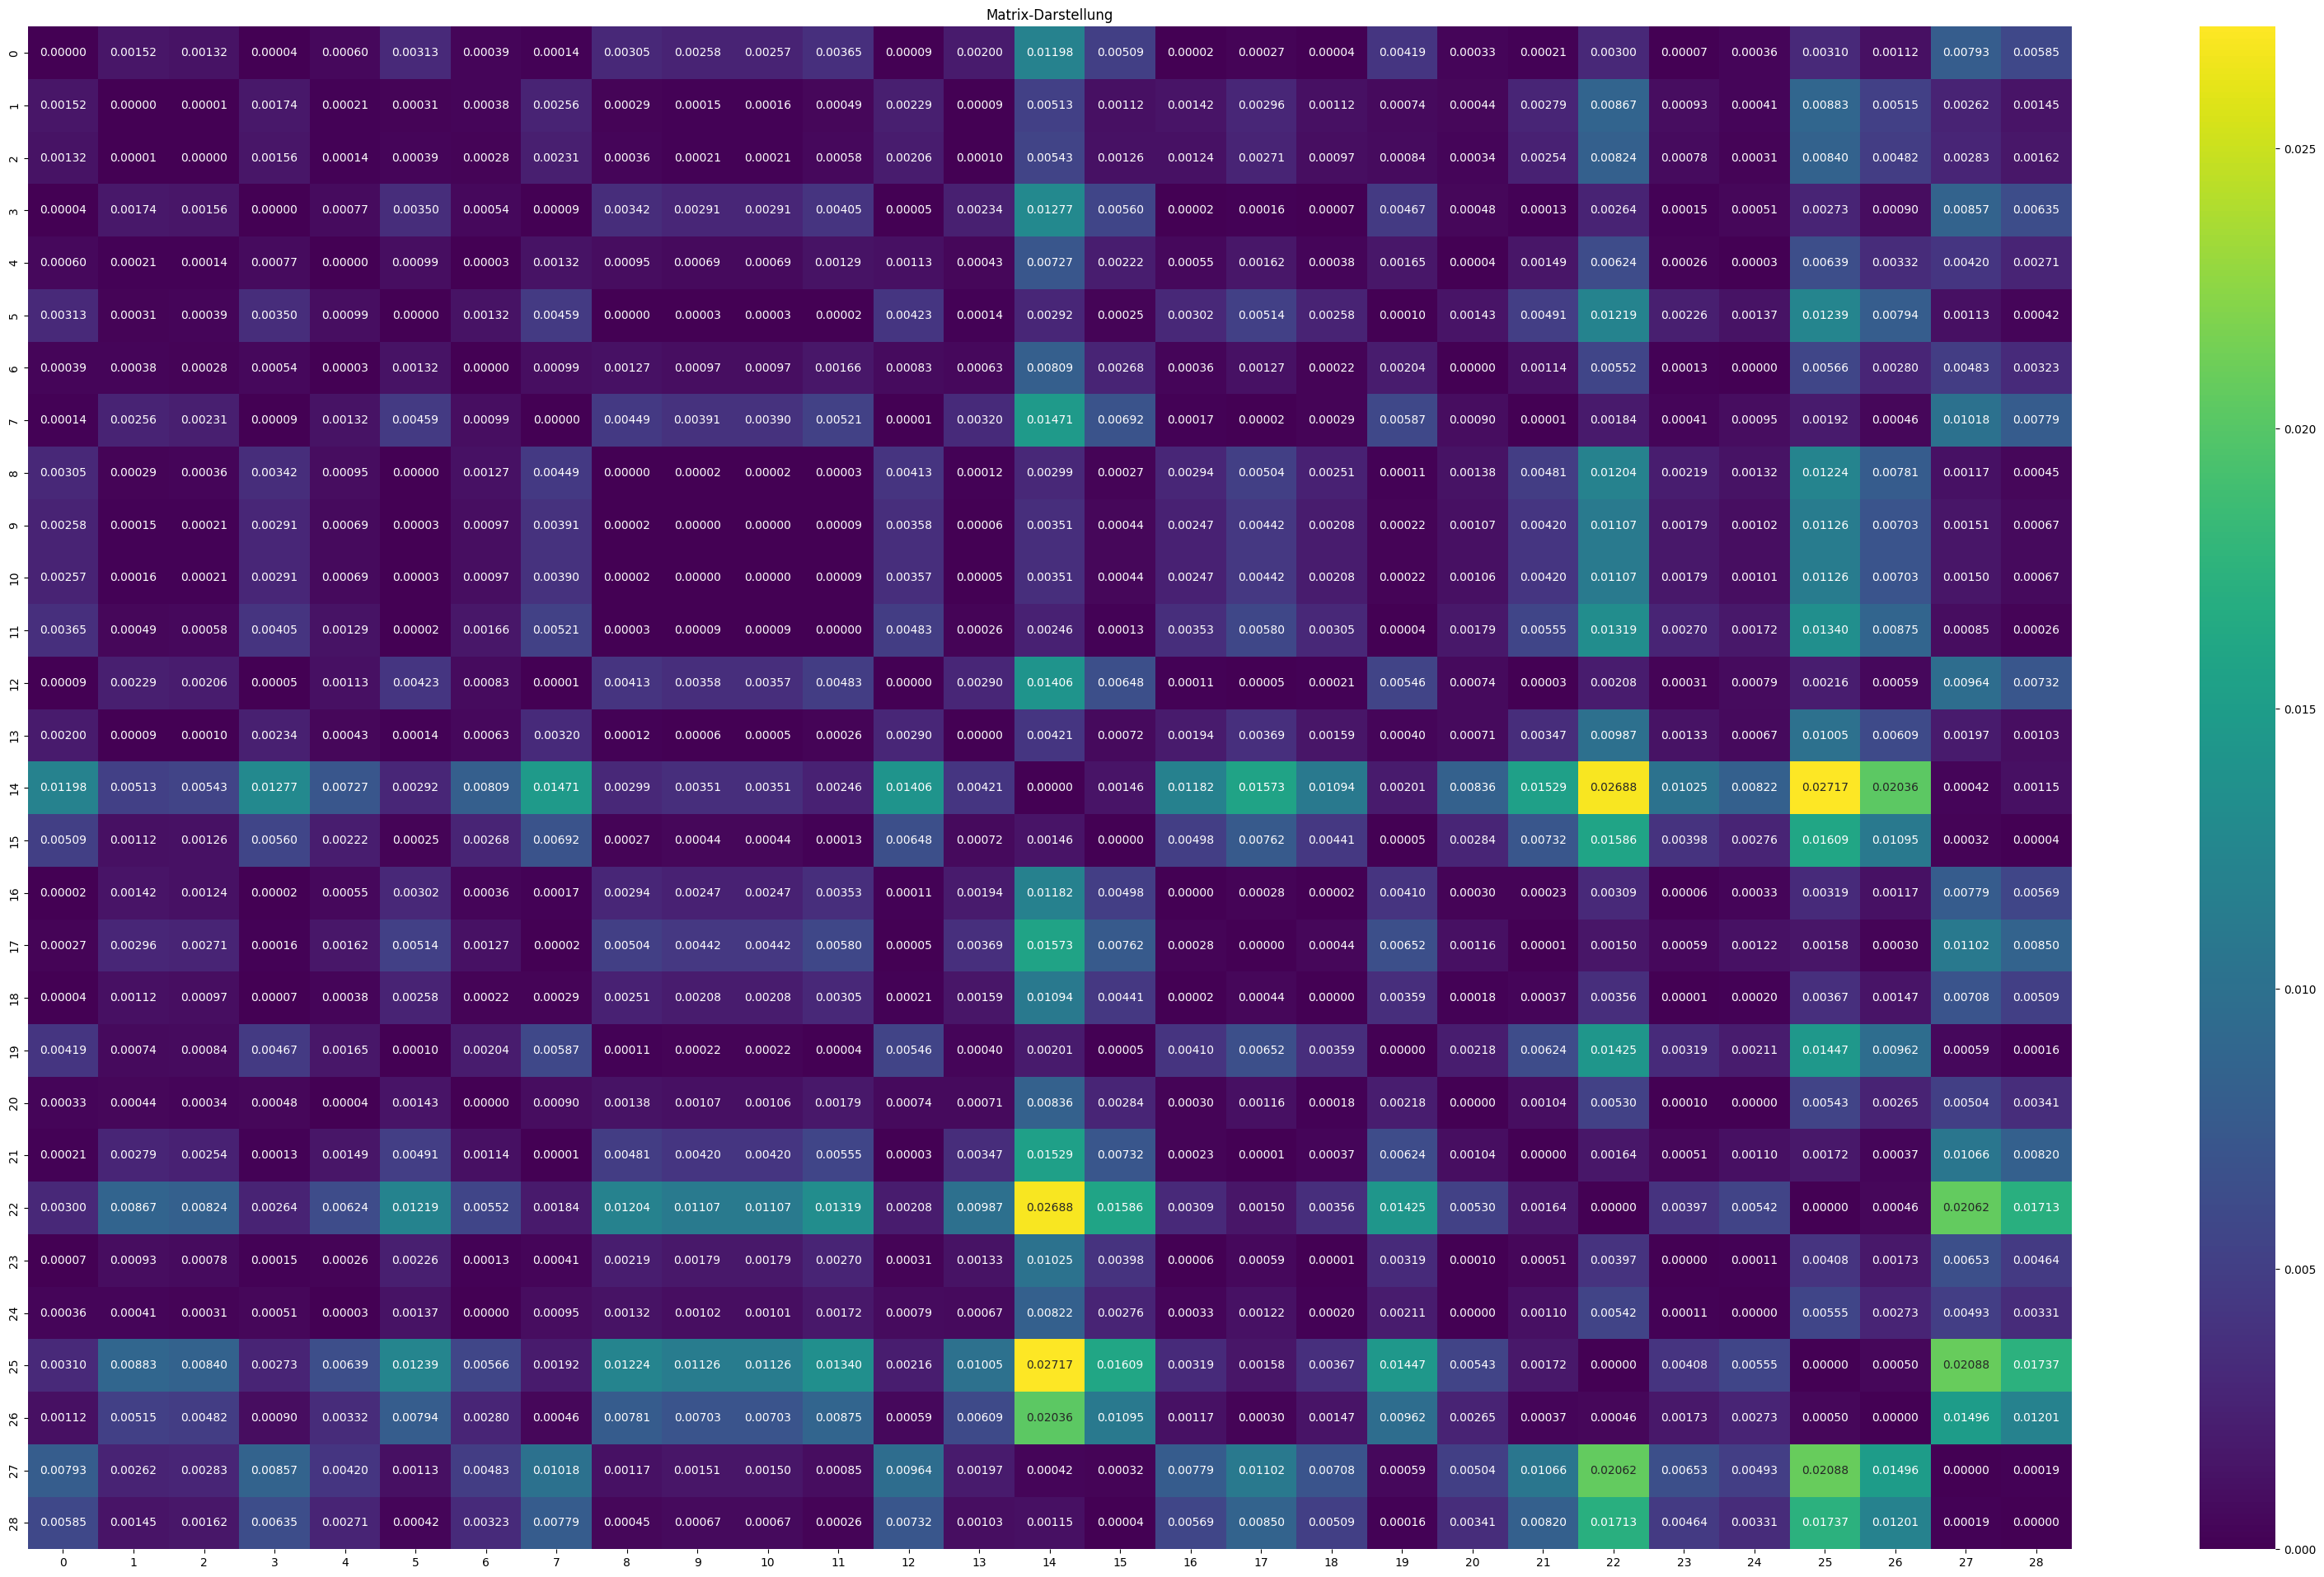

In [398]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame(corpus_matrix)

plt.figure(figsize=(40, 24))
sns.heatmap(df, annot=True, fmt=".5f", cmap="viridis")
plt.title("Matrix-Darstellung")
plt.show()


-----------------------------------------------------------------

# Decision Tree

In [399]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
from sklearn.metrics import confusion_matrix, classification_report
import sklearn.metrics as metrics

dtc = DecisionTreeClassifier()

avgwordlen, avgsenlen, avg_syll, wsf, fre_ger, ttr_erg, round(avg_punct[0],3), round(avg_punct[1],3), round(avg_punct[2],3), round(avg_punct[3],3), round(avg_punct[4],3), round(avg_punct[5],3)

(5.6, 12.9, 2.0, -0.29, 110.6, 0.2, 0.0, 0.0, 0.057, 0.054, 0.005, 0.005)

In [400]:
colu = ['AverageWordLength', 'AverageSentenceLength', 'AverageSyllables', 'WienerSachtextFormel', 'FRE_Ger', 'TTR', 'Avg !', 'Avg ?', 'Avg .', 'Avg ,', 'Avg ;', 'Avg :']
corp = pd.DataFrame(corpus_list)
corp.columns = colu
corp

,AverageWordLength,AverageSentenceLength,AverageSyllables,WienerSachtextFormel,FRE_Ger,TTR,Avg !,Avg ?,Avg .,"Avg ,",Avg ;,Avg :
0,4.8,22.8,1.6,1.11,100.3,0.14,0.003,0.002,0.033,0.082,0.011,0.003
1,5.8,18.0,1.9,0.63,105.4,0.22,0.013,0.003,0.036,0.061,0.005,0.003
2,5.5,18.3,1.8,0.56,105.0,0.17,0.022,0.007,0.032,0.062,0.001,0.002
3,5.5,23.2,1.8,1.43,100.1,0.16,0.018,0.004,0.024,0.071,0.002,0.004
4,5.3,19.8,1.7,0.72,103.4,0.17,0.017,0.004,0.030,0.066,0.004,0.004
5,5.5,15.7,1.8,0.18,107.6,0.15,0.032,0.005,0.029,0.062,0.002,0.005
6,5.0,20.4,1.7,0.80,102.8,0.17,0.010,0.007,0.029,0.087,0.002,0.002
7,4.9,24.2,1.6,1.45,98.9,0.16,0.007,0.002,0.032,0.070,0.006,0.005
8,5.4,15.8,1.8,0.16,107.5,0.20,0.001,0.003,0.051,0.073,0.000,0.000
9,5.5,16.4,1.8,0.29,106.9,0.20,0.001,0.002,0.049,0.074,0.000,0.000


In [401]:
corp["Author"]= ["aanrud", "achleitner", "achleitner", "achleitner", "achleitner", "achleitner", "alarcon", "alberti", "anonymous", "anonymous", "anonymous", "anonymous", "goethe", "goethe", "goethe", "goethe", "goethe", "goethe", "goethe", "heine", "kafka", "kafka", "kafka", "kafka", "kafka", "kafka", "kafka", "schiller", "westermann"]
corp

,AverageWordLength,AverageSentenceLength,AverageSyllables,WienerSachtextFormel,FRE_Ger,TTR,Avg !,Avg ?,Avg .,"Avg ,",Avg ;,Avg :,Author
0,4.8,22.8,1.6,1.11,100.3,0.14,0.003,0.002,0.033,0.082,0.011,0.003,aanrud
1,5.8,18.0,1.9,0.63,105.4,0.22,0.013,0.003,0.036,0.061,0.005,0.003,achleitner
2,5.5,18.3,1.8,0.56,105.0,0.17,0.022,0.007,0.032,0.062,0.001,0.002,achleitner
3,5.5,23.2,1.8,1.43,100.1,0.16,0.018,0.004,0.024,0.071,0.002,0.004,achleitner
4,5.3,19.8,1.7,0.72,103.4,0.17,0.017,0.004,0.030,0.066,0.004,0.004,achleitner
5,5.5,15.7,1.8,0.18,107.6,0.15,0.032,0.005,0.029,0.062,0.002,0.005,achleitner
6,5.0,20.4,1.7,0.80,102.8,0.17,0.010,0.007,0.029,0.087,0.002,0.002,alarcon
7,4.9,24.2,1.6,1.45,98.9,0.16,0.007,0.002,0.032,0.070,0.006,0.005,alberti
8,5.4,15.8,1.8,0.16,107.5,0.20,0.001,0.003,0.051,0.073,0.000,0.000,anonymous
9,5.5,16.4,1.8,0.29,106.9,0.20,0.001,0.002,0.049,0.074,0.000,0.000,anonymous


In [402]:
X = corp[colu] # Features
y = corp.Author # Target variable

In [403]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1) # 70% training and 30% test


In [404]:
# Create Decision Tree classifer object
clf = DecisionTreeClassifier()

# Train Decision Tree Classifer
clf = clf.fit(X_train,y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)


In [405]:
# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))


Accuracy: 0.4444444444444444


In [406]:
X = corp.iloc[:,0:12]
X

,AverageWordLength,AverageSentenceLength,AverageSyllables,WienerSachtextFormel,FRE_Ger,TTR,Avg !,Avg ?,Avg .,"Avg ,",Avg ;,Avg :
0,4.8,22.8,1.6,1.11,100.3,0.14,0.003,0.002,0.033,0.082,0.011,0.003
1,5.8,18.0,1.9,0.63,105.4,0.22,0.013,0.003,0.036,0.061,0.005,0.003
2,5.5,18.3,1.8,0.56,105.0,0.17,0.022,0.007,0.032,0.062,0.001,0.002
3,5.5,23.2,1.8,1.43,100.1,0.16,0.018,0.004,0.024,0.071,0.002,0.004
4,5.3,19.8,1.7,0.72,103.4,0.17,0.017,0.004,0.030,0.066,0.004,0.004
5,5.5,15.7,1.8,0.18,107.6,0.15,0.032,0.005,0.029,0.062,0.002,0.005
6,5.0,20.4,1.7,0.80,102.8,0.17,0.010,0.007,0.029,0.087,0.002,0.002
7,4.9,24.2,1.6,1.45,98.9,0.16,0.007,0.002,0.032,0.070,0.006,0.005
8,5.4,15.8,1.8,0.16,107.5,0.20,0.001,0.003,0.051,0.073,0.000,0.000
9,5.5,16.4,1.8,0.29,106.9,0.20,0.001,0.002,0.049,0.074,0.000,0.000


In [407]:
y = corp.iloc[:,12]
y

0         aanrud
1     achleitner
2     achleitner
3     achleitner
4     achleitner
5     achleitner
6        alarcon
7        alberti
8      anonymous
9      anonymous
10     anonymous
11     anonymous
12        goethe
13        goethe
14        goethe
15        goethe
16        goethe
17        goethe
18        goethe
19         heine
20         kafka
21         kafka
22         kafka
23         kafka
24         kafka
25         kafka
26         kafka
27      schiller
28    westermann
Name: Author, dtype: object

In [408]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=10, test_size=0.2)

In [409]:
X_train.shape

(23, 12)

In [410]:
X_test.shape

(6, 12)

In [411]:
y_train.shape

(23,)

In [412]:
y_test.shape

(6,)

In [413]:
dtc.get_params()

{'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': None,
 'splitter': 'best'}

In [414]:
dtc.fit(X_train, y_train)

DecisionTreeClassifier()

In [415]:
y_pred = dtc.predict(X_test)

In [416]:
print(confusion_matrix(y_test, y_pred))

[[0 0 0 0 0 0]
 [0 2 0 0 0 0]
 [1 0 0 0 0 0]
 [0 0 0 0 0 1]
 [0 0 0 0 2 0]
 [0 0 0 0 0 0]]


In [417]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      aanrud       0.00      0.00      0.00         0
  achleitner       1.00      1.00      1.00         2
     alberti       0.00      0.00      0.00         1
      goethe       0.00      0.00      0.00         1
       kafka       1.00      1.00      1.00         2
    schiller       0.00      0.00      0.00         0

    accuracy                           0.67         6
   macro avg       0.33      0.33      0.33         6
weighted avg       0.67      0.67      0.67         6



c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-l

In [418]:
dtc.feature_importances_

array([0.13537034, 0.        , 0.17403783, 0.        , 0.07876712,
       0.        , 0.22167319, 0.        , 0.        , 0.18058651,
       0.        , 0.20956501])

In [419]:
X.columns

Index(['AverageWordLength', 'AverageSentenceLength', 'AverageSyllables',
       'WienerSachtextFormel', 'FRE_Ger', 'TTR', 'Avg !', 'Avg ?', 'Avg .',
       'Avg ,', 'Avg ;', 'Avg :'],
      dtype='object')

In [420]:
features = pd.DataFrame(dtc.feature_importances_, index=X.columns)
features

,0
AverageWordLength,0.135370
AverageSentenceLength,0.000000
AverageSyllables,0.174038
WienerSachtextFormel,0.000000
FRE_Ger,0.078767
TTR,0.000000
Avg !,0.221673
Avg ?,0.000000
Avg .,0.000000
"Avg ,",0.180587


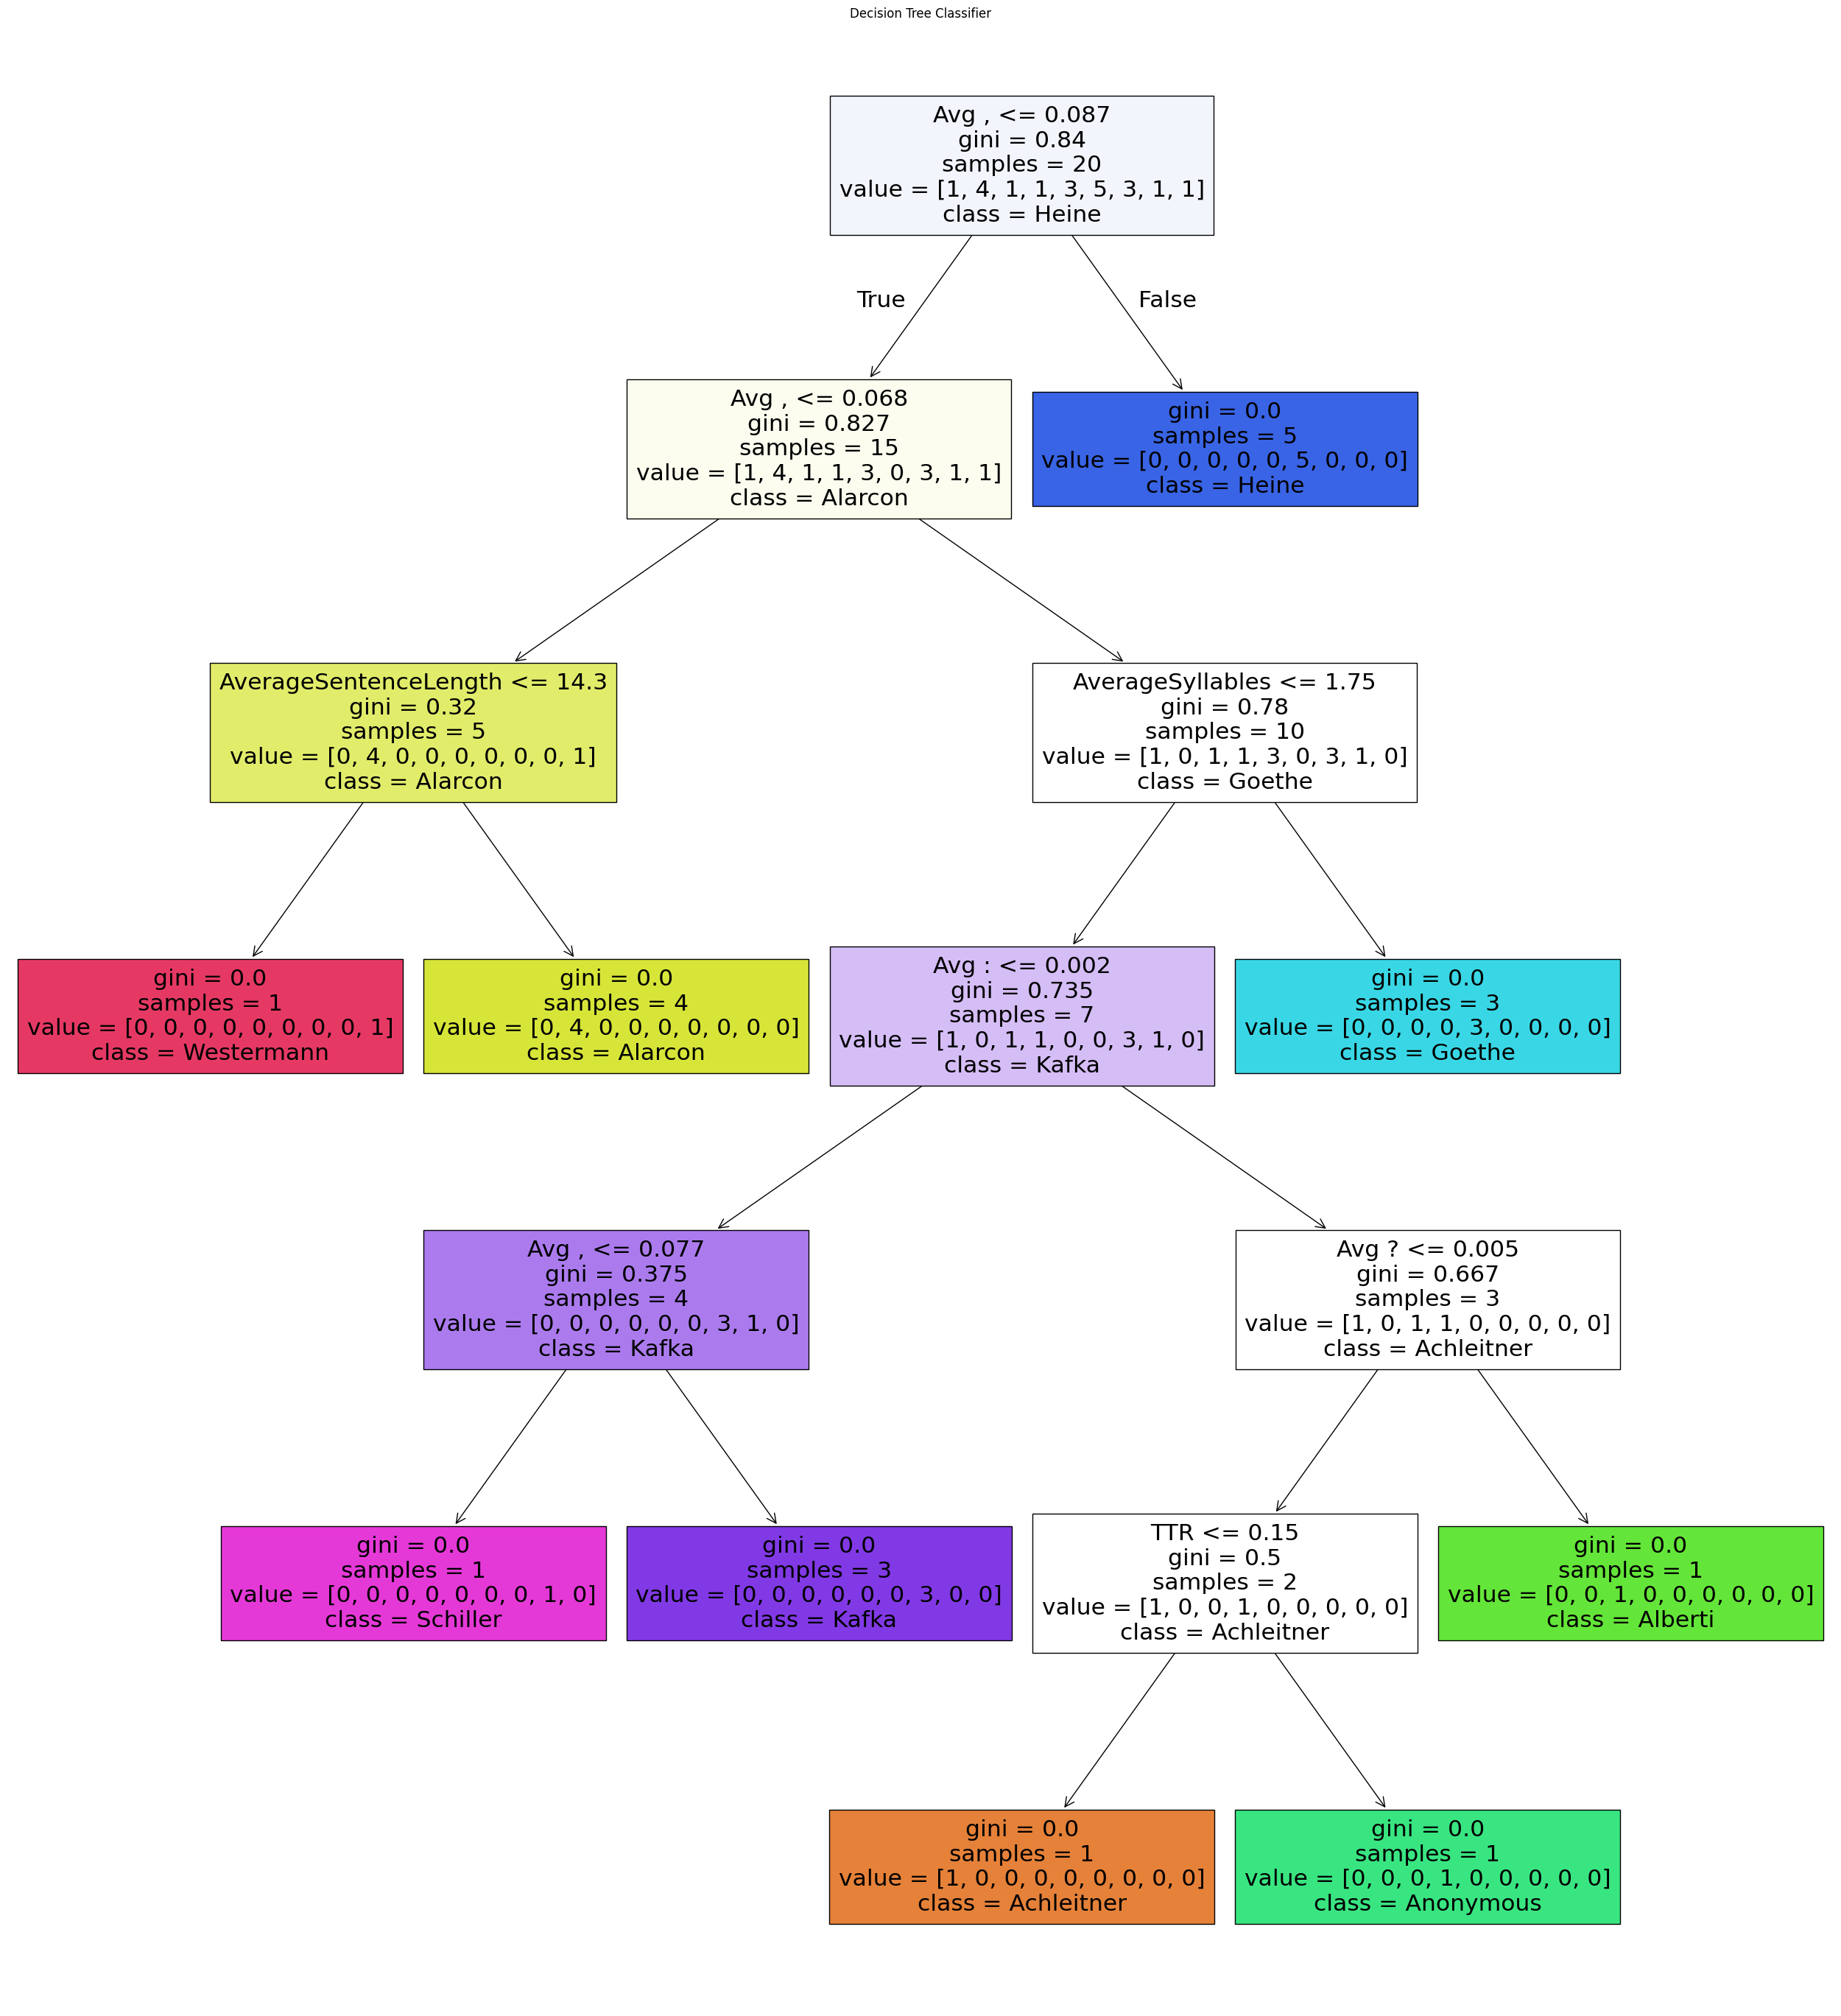

In [421]:
plt.figure(figsize=(32, 35))
tree.plot_tree(clf, filled=True, feature_names=X.columns, class_names=['Achleitner', 'Alarcon', 'Alberti', 'Anonymous', 'Goethe', 'Heine', 'Kafka', 'Schiller', 'Westermann'])
plt.title("Decision Tree Classifier")
plt.show()


In [422]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      aanrud       0.00      0.00      0.00         0
  achleitner       1.00      1.00      1.00         2
     alberti       0.00      0.00      0.00         1
      goethe       0.00      0.00      0.00         1
       kafka       1.00      1.00      1.00         2
    schiller       0.00      0.00      0.00         0

    accuracy                           0.67         6
   macro avg       0.33      0.33      0.33         6
weighted avg       0.67      0.67      0.67         6



c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-l

In [423]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import KFold, cross_val_score

k_folds = KFold(n_splits = 10)

scores = cross_val_score(clf, X, y, cv = k_folds)

print("Cross Validation Scores: ", scores)
print("Average CV Score: ", scores.mean())
print("Number of CV Scores used in Average: ", len(scores))

Cross Validation Scores:  [0.33333333 0.         0.33333333 1.         0.         0.66666667
 0.66666667 0.66666667 1.         0.        ]
Average CV Score:  0.4666666666666666
Number of CV Scores used in Average:  10


_______________________

# Random Forest

In [424]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier

In [425]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

classifier = RandomForestClassifier(n_estimators=1000, random_state=42)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

y_pred

array(['goethe', 'goethe', 'goethe', 'kafka', 'anonymous', 'anonymous'],
      dtype=object)

In [426]:
y_test

27     schiller
16       goethe
12       goethe
22        kafka
8     anonymous
9     anonymous
Name: Author, dtype: object

In [427]:
class_names=['Achleitner', 'Alarcon', 'Alberti', 'Anonymous', 'Goethe', 'Heine', 'Kafka', 'Schiller', 'Westermann']

Accuracy: 83.33%


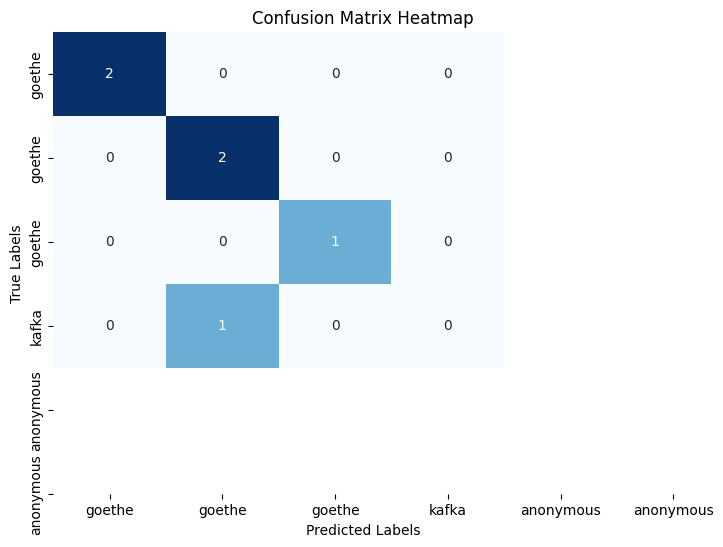

In [428]:
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')

conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='g', cmap='Blues', cbar=False, 
            xticklabels=y_pred, yticklabels=y_pred)

plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

In [429]:
conf_matrix

array([[2, 0, 0, 0],
       [0, 2, 0, 0],
       [0, 0, 1, 0],
       [0, 1, 0, 0]])

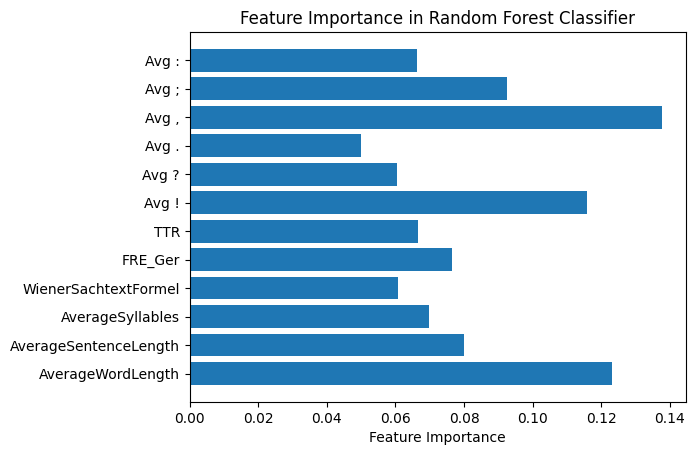

In [430]:
feature_importances = classifier.feature_importances_

plt.barh(X.columns, feature_importances)
plt.xlabel('Feature Importance')
plt.title('Feature Importance in Random Forest Classifier')
plt.show()

In [431]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

   anonymous       1.00      1.00      1.00         2
      goethe       0.67      1.00      0.80         2
       kafka       1.00      1.00      1.00         1
    schiller       0.00      0.00      0.00         1

    accuracy                           0.83         6
   macro avg       0.67      0.75      0.70         6
weighted avg       0.72      0.83      0.77         6



c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [432]:
k_folds = KFold(n_splits = 10)

scores = cross_val_score(clf, X, y, cv = k_folds)

print("Cross Validation Scores: ", scores)
print("Average CV Score: ", scores.mean())
print("Number of CV Scores used in Average: ", len(scores))

Cross Validation Scores:  [0.66666667 0.         0.33333333 1.         0.         1.
 0.66666667 0.33333333 1.         0.        ]
Average CV Score:  0.5
Number of CV Scores used in Average:  10


________________________

# Support Vector Machine

In [433]:
# Load the important packages
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.svm import SVC


In [434]:
X3 = X
y2 = y

In [435]:
X3

,AverageWordLength,AverageSentenceLength,AverageSyllables,WienerSachtextFormel,FRE_Ger,TTR,Avg !,Avg ?,Avg .,"Avg ,",Avg ;,Avg :
0,4.8,22.8,1.6,1.11,100.3,0.14,0.003,0.002,0.033,0.082,0.011,0.003
1,5.8,18.0,1.9,0.63,105.4,0.22,0.013,0.003,0.036,0.061,0.005,0.003
2,5.5,18.3,1.8,0.56,105.0,0.17,0.022,0.007,0.032,0.062,0.001,0.002
3,5.5,23.2,1.8,1.43,100.1,0.16,0.018,0.004,0.024,0.071,0.002,0.004
4,5.3,19.8,1.7,0.72,103.4,0.17,0.017,0.004,0.030,0.066,0.004,0.004
5,5.5,15.7,1.8,0.18,107.6,0.15,0.032,0.005,0.029,0.062,0.002,0.005
6,5.0,20.4,1.7,0.80,102.8,0.17,0.010,0.007,0.029,0.087,0.002,0.002
7,4.9,24.2,1.6,1.45,98.9,0.16,0.007,0.002,0.032,0.070,0.006,0.005
8,5.4,15.8,1.8,0.16,107.5,0.20,0.001,0.003,0.051,0.073,0.000,0.000
9,5.5,16.4,1.8,0.29,106.9,0.20,0.001,0.002,0.049,0.074,0.000,0.000


In [436]:
X2 = X3.drop(X3.columns[2:], axis=1)
X2

,AverageWordLength,AverageSentenceLength
0,4.8,22.8
1,5.8,18.0
2,5.5,18.3
3,5.5,23.2
4,5.3,19.8
5,5.5,15.7
6,5.0,20.4
7,4.9,24.2
8,5.4,15.8
9,5.5,16.4


In [437]:
y2 = corp.iloc[:,12]
y2

0         aanrud
1     achleitner
2     achleitner
3     achleitner
4     achleitner
5     achleitner
6        alarcon
7        alberti
8      anonymous
9      anonymous
10     anonymous
11     anonymous
12        goethe
13        goethe
14        goethe
15        goethe
16        goethe
17        goethe
18        goethe
19         heine
20         kafka
21         kafka
22         kafka
23         kafka
24         kafka
25         kafka
26         kafka
27      schiller
28    westermann
Name: Author, dtype: object

In [438]:
X_train, X_test, y_train, y_test = train_test_split(X2, y2, random_state=33, test_size=0.2)

### ---> Checking beste combination out of Kernel, Gamma & Regression

In [439]:
model_reg0 = SVC(C=0.1)
model_reg0.fit(X_train, y_train)
model_reg0.score(X_train, y_train)

0.30434782608695654

In [440]:
model_reg1 = SVC(C=1.0)
model_reg1.fit(X_train, y_train)
model_reg1.score(X_train, y_train)

0.34782608695652173

In [441]:
model_reg2 = SVC(C=1000)
model_reg2.fit(X_train, y_train)
model_reg2.score(X_train, y_train)

0.8260869565217391

In [442]:
model_gamma0 = SVC(gamma=0.1)
model_gamma0.fit(X_train, y_train)
model_gamma0.score(X_train, y_train)

0.6086956521739131

In [443]:
model_gamma1 = SVC(gamma=1)
model_gamma1.fit(X_train, y_train)
model_gamma1.score(X_train, y_train)

0.782608695652174

In [444]:
model_gamma2 = SVC(gamma=1000)
model_gamma2.fit(X_train, y_train)
model_gamma2.score(X_train, y_train)

1.0

In [445]:
model_linear = SVC(kernel="linear")
model_linear.fit(X_train, y_train)
model_linear.score(X_train, y_train)

0.4782608695652174

In [446]:
model_linear2 = SVC(kernel="rbf")
model_linear2.fit(X_train, y_train)
model_linear2.score(X_train, y_train)

0.34782608695652173

### Check completed <----

In [447]:
svm2 = SVC(kernel="linear", gamma=1000, C=1000)
svm2.fit(X_train, y_train)
svm2.score(X_train, y_train)

0.7391304347826086

In [448]:
color_map = {
    1: '#FF0000',   # red
    2: '#0000FF',   # blue
    3: '#008000',   # green
    4: '#FFA500',   # orange
    5: '#800080',   # purple
    6: '#FFFF00',   # yellow
    7: '#FF00FF',   # black
    8: '#000000',   # lime green
    9: '#A2C523',   # magenta
    10: "#48C5FF"   # sky blue
}

In [449]:
df_y2 = pd.DataFrame(y2)
werte = [1, 2, 2, 2, 2, 2, 3, 4, 5, 5, 5, 5, 6, 6, 6, 6, 6, 6, 6, 7, 8, 8, 8, 8, 8, 8, 8, 9, 10]
df_y2["Color"] = werte

In [450]:
df_y2['ColorName'] = df_y2['Color'].map(color_map)
df_y2

,Author,Color,ColorName
0,aanrud,1,#FF0000
1,achleitner,2,#0000FF
2,achleitner,2,#0000FF
3,achleitner,2,#0000FF
4,achleitner,2,#0000FF
5,achleitner,2,#0000FF
6,alarcon,3,#008000
7,alberti,4,#FFA500
8,anonymous,5,#800080
9,anonymous,5,#800080


In [451]:
from matplotlib.lines import Line2D
custom_legend = [
    Line2D([0], [0], marker='o', color='b', label='Aanrud', markerfacecolor='#FF0000', markersize=10),
    Line2D([0], [0], marker='o', color='b', label='Achleitner', markerfacecolor='#0000FF', markersize=10),
    Line2D([0], [0], marker='o', color='b', label='Alarcon', markerfacecolor='#008000', markersize=10),
    Line2D([0], [0], marker='o', color='b', label='Alberti', markerfacecolor='#FFA500', markersize=10),
    Line2D([0], [0], marker='o', color='b', label='Anonymous', markerfacecolor='#800080', markersize=10),
    Line2D([0], [0], marker='o', color='b', label='Goethe', markerfacecolor='#FFFF00', markersize=10),
    Line2D([0], [0], marker='o', color='b', label='Heine', markerfacecolor='#FF00FF', markersize=10),
    Line2D([0], [0], marker='o', color='b', label='Kafka', markerfacecolor='#000000', markersize=10),
    Line2D([0], [0], marker='o', color='b', label='Schiller', markerfacecolor='#A2C523', markersize=10),
    Line2D([0], [0], marker='o', color='b', label='Westermann', markerfacecolor="#48C5FF", markersize=10)
]

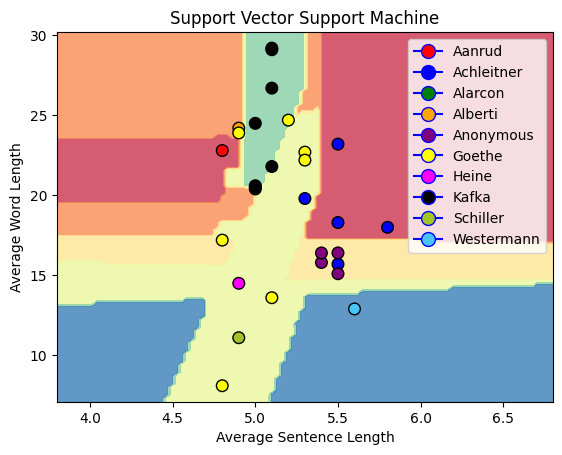

In [452]:
# Plot Decision Boundary
DecisionBoundaryDisplay.from_estimator(
        svm2,
        X2,
        response_method="predict",
        cmap=plt.cm.Spectral,
        alpha=0.8,
        xlabel=X2.columns[0],
        ylabel=X2.columns[1],
    )

# Scatter plot
#plt.figure(figsize=(10,26))
plt.title('Support Vector Support Machine')
plt.scatter(X2.iloc[:, 0], X2.iloc[:, 1], 
            c=df_y2['ColorName'], 
            s=70, edgecolors="k") #Alarcon liegt unter/hinter Kafka
plt.legend(handles=custom_legend)
plt.xlabel("Average Sentence Length")
plt.ylabel("Average Word Length")
#plt.colorbar()
plt.show()

In [453]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

  achleitner       0.00      0.00      0.00         2
   anonymous       0.50      0.50      0.50         2
      goethe       0.67      1.00      0.80         2
       kafka       0.00      0.00      0.00         0

    accuracy                           0.50         6
   macro avg       0.29      0.38      0.33         6
weighted avg       0.39      0.50      0.43         6



c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-l

In [454]:
k_folds = KFold(n_splits = 10)

scores = cross_val_score(clf, X2, y2, cv = k_folds)

print("Cross Validation Scores: ", scores)
print("Average CV Score: ", scores.mean())
print("Number of CV Scores used in Average: ", len(scores))

Cross Validation Scores:  [0.         0.33333333 0.         0.33333333 0.         0.33333333
 0.66666667 0.66666667 0.66666667 0.        ]
Average CV Score:  0.29999999999999993
Number of CV Scores used in Average:  10


### Multimodal Arrays

In [455]:
corp

,AverageWordLength,AverageSentenceLength,AverageSyllables,WienerSachtextFormel,FRE_Ger,TTR,Avg !,Avg ?,Avg .,"Avg ,",Avg ;,Avg :,Author
0,4.8,22.8,1.6,1.11,100.3,0.14,0.003,0.002,0.033,0.082,0.011,0.003,aanrud
1,5.8,18.0,1.9,0.63,105.4,0.22,0.013,0.003,0.036,0.061,0.005,0.003,achleitner
2,5.5,18.3,1.8,0.56,105.0,0.17,0.022,0.007,0.032,0.062,0.001,0.002,achleitner
3,5.5,23.2,1.8,1.43,100.1,0.16,0.018,0.004,0.024,0.071,0.002,0.004,achleitner
4,5.3,19.8,1.7,0.72,103.4,0.17,0.017,0.004,0.030,0.066,0.004,0.004,achleitner
5,5.5,15.7,1.8,0.18,107.6,0.15,0.032,0.005,0.029,0.062,0.002,0.005,achleitner
6,5.0,20.4,1.7,0.80,102.8,0.17,0.010,0.007,0.029,0.087,0.002,0.002,alarcon
7,4.9,24.2,1.6,1.45,98.9,0.16,0.007,0.002,0.032,0.070,0.006,0.005,alberti
8,5.4,15.8,1.8,0.16,107.5,0.20,0.001,0.003,0.051,0.073,0.000,0.000,anonymous
9,5.5,16.4,1.8,0.29,106.9,0.20,0.001,0.002,0.049,0.074,0.000,0.000,anonymous


In [456]:
X

,AverageWordLength,AverageSentenceLength,AverageSyllables,WienerSachtextFormel,FRE_Ger,TTR,Avg !,Avg ?,Avg .,"Avg ,",Avg ;,Avg :
0,4.8,22.8,1.6,1.11,100.3,0.14,0.003,0.002,0.033,0.082,0.011,0.003
1,5.8,18.0,1.9,0.63,105.4,0.22,0.013,0.003,0.036,0.061,0.005,0.003
2,5.5,18.3,1.8,0.56,105.0,0.17,0.022,0.007,0.032,0.062,0.001,0.002
3,5.5,23.2,1.8,1.43,100.1,0.16,0.018,0.004,0.024,0.071,0.002,0.004
4,5.3,19.8,1.7,0.72,103.4,0.17,0.017,0.004,0.030,0.066,0.004,0.004
5,5.5,15.7,1.8,0.18,107.6,0.15,0.032,0.005,0.029,0.062,0.002,0.005
6,5.0,20.4,1.7,0.80,102.8,0.17,0.010,0.007,0.029,0.087,0.002,0.002
7,4.9,24.2,1.6,1.45,98.9,0.16,0.007,0.002,0.032,0.070,0.006,0.005
8,5.4,15.8,1.8,0.16,107.5,0.20,0.001,0.003,0.051,0.073,0.000,0.000
9,5.5,16.4,1.8,0.29,106.9,0.20,0.001,0.002,0.049,0.074,0.000,0.000


In [457]:
import numpy as np
print(type(X))
arr = np.array(X)

X_flattend = arr.reshape(174,2)
X_flattend

<class 'pandas.core.frame.DataFrame'>


array([[ 4.800e+00,  2.280e+01],
       [ 1.600e+00,  1.110e+00],
       [ 1.003e+02,  1.400e-01],
       [ 3.000e-03,  2.000e-03],
       [ 3.300e-02,  8.200e-02],
       [ 1.100e-02,  3.000e-03],
       [ 5.800e+00,  1.800e+01],
       [ 1.900e+00,  6.300e-01],
       [ 1.054e+02,  2.200e-01],
       [ 1.300e-02,  3.000e-03],
       [ 3.600e-02,  6.100e-02],
       [ 5.000e-03,  3.000e-03],
       [ 5.500e+00,  1.830e+01],
       [ 1.800e+00,  5.600e-01],
       [ 1.050e+02,  1.700e-01],
       [ 2.200e-02,  7.000e-03],
       [ 3.200e-02,  6.200e-02],
       [ 1.000e-03,  2.000e-03],
       [ 5.500e+00,  2.320e+01],
       [ 1.800e+00,  1.430e+00],
       [ 1.001e+02,  1.600e-01],
       [ 1.800e-02,  4.000e-03],
       [ 2.400e-02,  7.100e-02],
       [ 2.000e-03,  4.000e-03],
       [ 5.300e+00,  1.980e+01],
       [ 1.700e+00,  7.200e-01],
       [ 1.034e+02,  1.700e-01],
       [ 1.700e-02,  4.000e-03],
       [ 3.000e-02,  6.600e-02],
       [ 4.000e-03,  4.000e-03],
       [ 5

In [458]:
X_df = pd.DataFrame(X_flattend)
class_names2 = [(['Aanrud'] * 6) * 1 + (['Achleitner'] * 6) * 5 + (['Alarcon'] * 6) * 1 + (['Alberti'] * 6) * 1 + (['Anonymous'] * 6) * 4 +
               (['Goethe'] * 6) * 7 + (['Heine'] * 6) * 1 + (['Kafka'] * 6) * 7 + (['Schiller'] * 6) * 1 + (['Westermann'] * 6) * 1]
class_names_multi = pd.DataFrame(class_names2[0])
color_codes2 = [(['#FF0000'] * 6) * 1 + (['#0000FF'] * 6) * 5 + (['#008000'] * 6) * 1 + (['#FFA500'] * 6) * 1 + (['#800080'] * 6) * 4 +
               (['#FFFF00'] * 6) * 7 + (['#000000'] * 6) * 1 + (['#A2C523'] * 6) * 7 + (['#FF00FF'] * 6) * 1 + (['#48C5FF'] * 6) * 1]
color_codes = pd.DataFrame(color_codes2[0])
class_names_multi["color"] = color_codes
class_names_multi

,0,color
0,Aanrud,#FF0000
1,Aanrud,#FF0000
2,Aanrud,#FF0000
3,Aanrud,#FF0000
4,Aanrud,#FF0000
...,...,...
169,Westermann,#48C5FF
170,Westermann,#48C5FF
171,Westermann,#48C5FF
172,Westermann,#48C5FF


In [459]:
X_train, X_test, y_train, y_test = train_test_split(X_flattend, class_names_multi[0], random_state=10, test_size=0.2)

In [460]:
svm2 = SVC(kernel="rbf", gamma=1000)
svm2.fit(X_train, y_train)
svm2.score(X_train, y_train)

0.6906474820143885

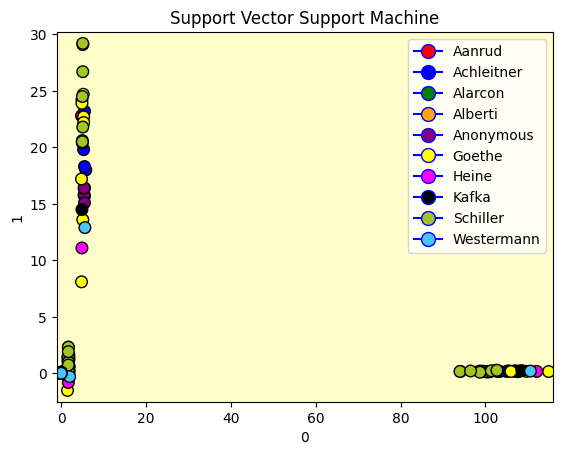

In [461]:
# Plot Decision Boundary
DecisionBoundaryDisplay.from_estimator(
        svm2,
        X_df,
        response_method="predict",
        cmap=plt.cm.Spectral,
        alpha=0.8,
        xlabel=X_df.columns[0],
        ylabel=X_df.columns[1],
    )

# Scatter plot
#plt.figure(figsize=(10,26))
plt.title('Support Vector Support Machine')
plt.scatter(X_df.iloc[:, 0], X_df.iloc[:, 1], 
            c=class_names_multi['color'], 
            s=70, edgecolors="k") #Alarcon liegt unter/hinter Kafka
plt.legend(handles=custom_legend)
#plt.xlabel("Average Sentence Length")
#plt.ylabel("Average Word Length")
#plt.colorbar()
plt.show()

In [462]:
y_pred

array(['goethe', 'goethe', 'goethe', 'kafka', 'anonymous', 'anonymous'],
      dtype=object)

In [463]:
y_test

112        Goethe
19     Achleitner
68      Anonymous
106        Goethe
66      Anonymous
67      Anonymous
90         Goethe
47        Alberti
10     Achleitner
49      Anonymous
150         Kafka
98         Goethe
59      Anonymous
99         Goethe
170    Westermann
20     Achleitner
81         Goethe
39        Alarcon
111        Goethe
1          Aanrud
76         Goethe
121         Kafka
145         Kafka
166      Schiller
102        Goethe
105        Goethe
72         Goethe
130         Kafka
110        Goethe
146         Kafka
136         Kafka
143         Kafka
164      Schiller
120         Kafka
26     Achleitner
Name: 0, dtype: object

In [464]:
print(classification_report(y_test, y_pred)) #ist das überhaupt richtig an dieser Stelle? 

ValueError: Found input variables with inconsistent numbers of samples: [35, 6]

In [ ]:
model_reg0 = SVC(C=0.1)
model_reg0.fit(X_train, y_train)
model_reg0.score(X_train, y_train)

0.2446043165467626

In [ ]:
model_reg1 = SVC(C=1.0)
model_reg1.fit(X_train, y_train)
model_reg1.score(X_train, y_train)

0.24691358024691357

In [ ]:
model_reg2 = SVC(C=1000)
model_reg2.fit(X_train, y_train)
model_reg2.score(X_train, y_train)

0.345679012345679

In [ ]:
model_gamma0 = SVC(gamma=0.1)
model_gamma0.fit(X_train, y_train)
model_gamma0.score(X_train, y_train)

0.3333333333333333

In [ ]:
model_gamma1 = SVC(gamma=1)
model_gamma1.fit(X_train, y_train)
model_gamma1.score(X_train, y_train)

0.4567901234567901

In [ ]:
model_gamma2 = SVC(gamma=1000)
model_gamma2.fit(X_train, y_train)
model_gamma2.score(X_train, y_train)

0.6419753086419753

In [ ]:
model_linear = SVC(kernel="linear")
model_linear.fit(X_train, y_train)
model_linear.score(X_train, y_train)

0.2345679012345679

In [ ]:
model_linear2 = SVC(kernel="rbf")
model_linear2.fit(X_train, y_train)
model_linear2.score(X_train, y_train)

0.24691358024691357

In [ ]:
from sklearn import datasets
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import KFold, cross_val_score

X, y = datasets.load_iris(return_X_y=True)

clf = DecisionTreeClassifier(random_state=42)

k_folds = KFold(n_splits = 10)

scores = cross_val_score(clf, X, y, cv = k_folds)

print("Cross Validation Scores: ", scores)
print("Average CV Score: ", scores.mean())
print("Number of CV Scores used in Average: ", len(scores))

Cross Validation Scores:  [1.         1.         1.         0.93333333 0.93333333 0.86666667
 1.         0.86666667 0.93333333 1.        ]
Average CV Score:  0.9533333333333334
Number of CV Scores used in Average:  10
